In [11]:
%pip install -q duckdb pyarrow "fg-data-profiling[notebook]" "setuptools<82"


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [18]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

%matplotlib inline

In [12]:
from pathlib import Path
import tempfile

import duckdb
import pandas as pd
import pyarrow.parquet as pq

DATA_DIR = Path("data").resolve()
OUTPUT_DIR = Path("output").resolve()
TEMP_DIR = Path(tempfile.gettempdir()) / "tlc_duckdb"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TEMP_DIR.mkdir(parents=True, exist_ok=True)

PARQUET_GLOB = str(DATA_DIR / "*.parquet")
PARQUET_GLOB_SQL = PARQUET_GLOB.replace("'", "''")
TEMP_DIR_SQL = str(TEMP_DIR).replace("'", "''")

In [4]:
parquet_files = sorted(DATA_DIR.glob("*.parquet"))

if not parquet_files:
    raise FileNotFoundError(f"В {DATA_DIR} не найдены Parquet-файлы")

file_inventory = pd.DataFrame(
    {
        "file": path.name,
        "rows": pq.read_metadata(path).num_rows,
        "size_gb": path.stat().st_size / 1_000_000_000,
    }
    for path in parquet_files
)

display(file_inventory)
print(f"Файлов: {len(file_inventory)}")
print(f"Строк: {file_inventory['rows'].sum():,}")
print(f"Размер на диске: {file_inventory['size_gb'].sum():.2f} GB")

,file,rows,size_gb
0,fhvhv_tripdata_2025-01.parquet,20405666,0.491077
1,fhvhv_tripdata_2025-02.parquet,19339461,0.461632
2,fhvhv_tripdata_2025-03.parquet,20536879,0.501784
3,fhvhv_tripdata_2025-04.parquet,19753983,0.487220
4,fhvhv_tripdata_2025-05.parquet,21091193,0.517387
5,fhvhv_tripdata_2025-06.parquet,19868009,0.490819
6,fhvhv_tripdata_2025-07.parquet,19653012,0.487223
7,fhvhv_tripdata_2025-08.parquet,19271461,0.479575
8,fhvhv_tripdata_2025-09.parquet,19434641,0.480851
9,fhvhv_tripdata_2025-10.parquet,21308701,0.518486


Файлов: 16
Строк: 327,460,054
Размер на диске: 7.98 GB


In [14]:
con = duckdb.connect()
con.execute("SET memory_limit = '8GB'")
con.execute("SET threads = 4")
con.execute(f"SET temp_directory = '{TEMP_DIR_SQL}'")

con.execute(
    f"""
    CREATE OR REPLACE VIEW trips AS
    SELECT *
    FROM read_parquet(
        '{PARQUET_GLOB_SQL}',
        filename = true
    )
    """
)

In [15]:
schema = con.sql("DESCRIBE trips").df()
schema

,column_name,column_type,null,key,default,extra
0,hvfhs_license_num,VARCHAR,YES,None,None,None
1,dispatching_base_num,VARCHAR,YES,None,None,None
2,originating_base_num,VARCHAR,YES,None,None,None
3,request_datetime,TIMESTAMP,YES,None,None,None
4,on_scene_datetime,TIMESTAMP,YES,None,None,None
5,pickup_datetime,TIMESTAMP,YES,None,None,None
6,dropoff_datetime,TIMESTAMP,YES,None,None,None
7,PULocationID,INTEGER,YES,None,None,None
8,DOLocationID,INTEGER,YES,None,None,None
9,trip_miles,DOUBLE,YES,None,None,None


In [16]:
quality = con.sql(
    """
    WITH checks AS (
        SELECT
            filename,
            request_datetime,
            pickup_datetime,
            dropoff_datetime,
            date_diff('second', request_datetime, pickup_datetime) AS wait_seconds,
            trip_time,
            trip_miles
        FROM trips
    )
    SELECT
        count(*) AS rows,
        count(DISTINCT filename) AS files,
        min(pickup_datetime) AS first_pickup,
        max(pickup_datetime) AS last_pickup,
        count(*) FILTER (WHERE request_datetime IS NULL) AS missing_request_datetime,
        count(*) FILTER (WHERE pickup_datetime IS NULL) AS missing_pickup_datetime,
        count(*) FILTER (WHERE dropoff_datetime IS NULL) AS missing_dropoff_datetime,
        count(*) FILTER (WHERE wait_seconds < 0 OR wait_seconds > 7200) AS invalid_wait,
        count(*) FILTER (WHERE trip_time <= 0) AS non_positive_trip_time,
        count(*) FILTER (WHERE trip_miles < 0) AS negative_trip_miles
    FROM checks
    """
).df()

quality.T

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,0
rows,327460054
files,16
first_pickup,2025-01-01 00:00:00
last_pickup,2026-04-30 23:59:59
missing_request_datetime,0
missing_pickup_datetime,0
missing_dropoff_datetime,0
invalid_wait,3904101
non_positive_trip_time,1423
negative_trip_miles,0


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

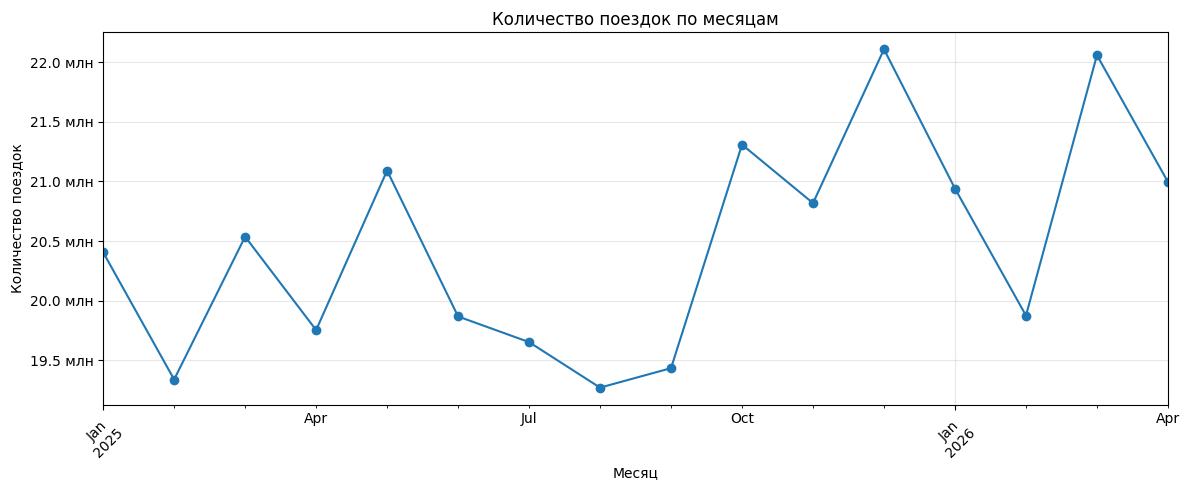

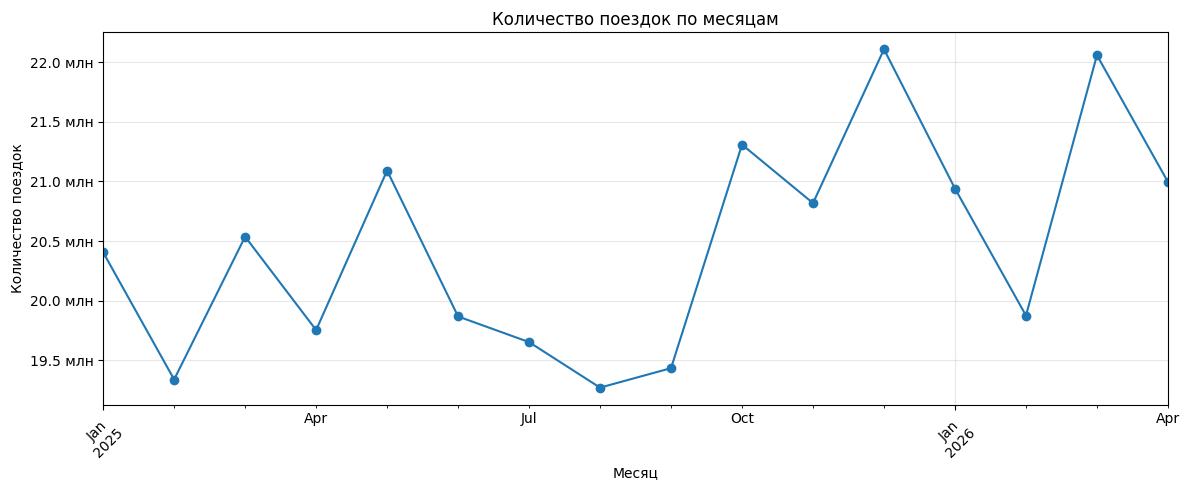

In [19]:
monthly_trips = con.sql(
    """
    SELECT
        date_trunc('month', pickup_datetime) AS month,
        count(*) AS trips
    FROM trips
    WHERE pickup_datetime IS NOT NULL
    GROUP BY 1
    ORDER BY 1
    """
).df()

ax = monthly_trips.plot(
    x="month",
    y="trips",
    marker="o",
    figsize=(12, 5),
    legend=False,
)

ax.set_title("Количество поездок по месяцам")
ax.set_xlabel("Месяц")
ax.set_ylabel("Количество поездок")
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, _: f"{value / 1_000_000:.1f} млн")
)
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 2. Пропуски во всех полях

In [20]:
columns = schema["column_name"].tolist()

def quote_identifier(name):
    return '"' + name.replace('"', '""') + '"'

missing_expressions = [
    f"count(*) FILTER (WHERE {quote_identifier(column)} IS NULL) AS {quote_identifier(column)}"
    for column in columns
]

missing_counts = con.sql(
    "SELECT\n        count(*) AS total_rows,\n        "
    + ",\n        ".join(missing_expressions)
    + "\nFROM trips"
).df()

total_rows = int(missing_counts.at[0, "total_rows"])
missing_report = (
    missing_counts.drop(columns="total_rows")
    .T.rename(columns={0: "missing_rows"})
    .rename_axis("column")
    .reset_index()
)
missing_report["missing_pct"] = (
    missing_report["missing_rows"] / total_rows * 100
).round(4)

missing_report.sort_values(
    ["missing_rows", "column"],
    ascending=[False, True],
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,column,missing_rows,missing_pct
2,originating_base_num,90426873,27.6146
4,on_scene_datetime,10870353,3.3196
8,DOLocationID,0,0.0000
7,PULocationID,0,0.0000
21,access_a_ride_flag,0,0.0000
16,airport_fee,0,0.0000
11,base_passenger_fare,0,0.0000
13,bcf,0,0.0000
24,cbd_congestion_fee,0,0.0000
15,congestion_surcharge,0,0.0000


## 3. Хронологический порядок значений

Проверка порядка `request_datetime → on_scene_datetime → pickup_datetime → dropoff_datetime`. Пропуски анализируются отдельно в предыдущей проверке.

In [ ]:
chronology_report = con.sql(
    """
    SELECT
        count(*) AS total_rows,
        count(*) FILTER (
            WHERE request_datetime > pickup_datetime
        ) AS request_after_pickup,
        count(*) FILTER (
            WHERE on_scene_datetime IS NOT NULL
              AND request_datetime > on_scene_datetime
        ) AS on_scene_before_request,
        count(*) FILTER (
            WHERE on_scene_datetime IS NOT NULL
              AND on_scene_datetime > pickup_datetime
        ) AS on_scene_after_pickup,
        count(*) FILTER (
            WHERE pickup_datetime >= dropoff_datetime
        ) AS pickup_not_before_dropoff,
        count(*) FILTER (
            WHERE request_datetime > pickup_datetime
               OR (
                    on_scene_datetime IS NOT NULL
                    AND request_datetime > on_scene_datetime
               )
               OR (
                    on_scene_datetime IS NOT NULL
                    AND on_scene_datetime > pickup_datetime
               )
               OR pickup_datetime >= dropoff_datetime
        ) AS rows_with_invalid_chronology
    FROM trips
    """
).df()

chronology_report.T.rename(columns={0: "rows"})

## 6. Некорректные расстояния и длительности

Проверка отрицательных и нулевых значений, а также расхождения `trip_time` с длительностью между посадкой и высадкой. Подозрительные сочетания следует изучить до удаления строк.

In [ ]:
distance_duration_report = con.sql(
    """
    WITH checks AS (
        SELECT
            trip_miles,
            trip_time,
            date_diff(
                'second',
                pickup_datetime,
                dropoff_datetime
            ) AS datetime_trip_seconds
        FROM trips
    )
    SELECT
        count(*) AS total_rows,
        count(*) FILTER (WHERE trip_miles < 0) AS negative_trip_miles,
        count(*) FILTER (WHERE trip_miles = 0) AS zero_trip_miles,
        count(*) FILTER (WHERE trip_time <= 0) AS non_positive_trip_time,
        count(*) FILTER (
            WHERE datetime_trip_seconds <= 0
        ) AS non_positive_datetime_duration,
        count(*) FILTER (
            WHERE trip_miles = 0 AND trip_time > 0
        ) AS zero_distance_with_positive_time,
        count(*) FILTER (
            WHERE trip_miles > 0 AND trip_time <= 0
        ) AS positive_distance_with_non_positive_time,
        count(*) FILTER (
            WHERE trip_time IS NOT NULL
              AND datetime_trip_seconds IS NOT NULL
              AND abs(trip_time - datetime_trip_seconds) > 60
        ) AS duration_difference_over_60_seconds
    FROM checks
    """
).df()

distance_duration_report.T.rename(columns={0: "rows"})

## 9. Денежные поля

Проверка отрицательных и нулевых значений, минимума, медианы, 99-го перцентиля и максимума. Отрицательное значение сначала следует рассматривать как возможную корректировку, а не автоматически удалять.

In [ ]:
money_columns = [
    "base_passenger_fare",
    "tolls",
    "bcf",
    "sales_tax",
    "congestion_surcharge",
    "airport_fee",
    "tips",
    "driver_pay",
    "cbd_congestion_fee",
]

money_expressions = []
for column in money_columns:
    identifier = quote_identifier(column)
    money_expressions.extend(
        [
            f"count(*) FILTER (WHERE {identifier} < 0) AS {quote_identifier(column + '__negative_rows')}",
            f"count(*) FILTER (WHERE {identifier} = 0) AS {quote_identifier(column + '__zero_rows')}",
            f"min({identifier}) AS {quote_identifier(column + '__min')}",
            f"approx_quantile({identifier}, 0.5) AS {quote_identifier(column + '__median')}",
            f"approx_quantile({identifier}, 0.99) AS {quote_identifier(column + '__p99')}",
            f"max({identifier}) AS {quote_identifier(column + '__max')}",
        ]
    )

money_wide = con.sql(
    "SELECT\n        "
    + ",\n        ".join(money_expressions)
    + "\nFROM trips"
).df()

money_report = pd.DataFrame(
    [
        {
            "column": column,
            "negative_rows": money_wide.at[0, f"{column}__negative_rows"],
            "zero_rows": money_wide.at[0, f"{column}__zero_rows"],
            "min": money_wide.at[0, f"{column}__min"],
            "median": money_wide.at[0, f"{column}__median"],
            "p99": money_wide.at[0, f"{column}__p99"],
            "max": money_wide.at[0, f"{column}__max"],
        }
        for column in money_columns
    ]
)

money_report

## 15. Полные дубликаты

Точная проверка строк, одинаковых по всем исходным полям. Это самая ресурсоёмкая проверка: хеш используется только для предварительного отбора кандидатов, после чего совпадения подтверждаются сравнением всех колонок. Поле `filename` не участвует, поэтому находятся и дубликаты между разными файлами.

In [ ]:
duplicate_columns = [
    column for column in schema["column_name"] if column != "filename"
]
hash_arguments = ", ".join(
    quote_identifier(column) for column in duplicate_columns
)
hash_arguments_with_alias = ", ".join(
    f"t.{quote_identifier(column)}" for column in duplicate_columns
)

duplicate_report = con.sql(
    f"""
    WITH candidate_hashes AS (
        SELECT hash({hash_arguments}) AS row_hash
        FROM trips
        GROUP BY row_hash
        HAVING count(*) > 1
    ),
    duplicate_groups AS (
        SELECT
            t.* EXCLUDE (filename),
            count(*) AS duplicate_count
        FROM trips AS t
        SEMI JOIN candidate_hashes AS candidates
            ON hash({hash_arguments_with_alias}) = candidates.row_hash
        GROUP BY ALL
        HAVING count(*) > 1
    )
    SELECT
        count(*) AS duplicate_groups,
        coalesce(sum(duplicate_count), 0) AS rows_in_duplicate_groups,
        coalesce(sum(duplicate_count - 1), 0) AS extra_duplicate_rows
    FROM duplicate_groups
    """
).df()

duplicate_report